# JS07 - Klasterisasi | Lab 2
## Bagaimana Jika Data Non-Linear? (DBSCAN)

**Nama:** Gunawan Wibisono
**NIM:** 244107020132
**Kelas:** TI-2H

> Modul: [JTI - Modul Praktikum Pembelajaran Mesin - JS07 Klasterisasi](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-mah/js07-klasterisasi)

## Tujuan
1. Menunjukkan keterbatasan K-Means pada data yang tidak terpisah secara linear.
2. Mampu membangun model DBSCAN dan memahami pengaruh parameter `eps` dan `min_samples`.
3. Mampu mengevaluasi klasterisasi dengan *silhouette score* dan *Davies-Bouldin Index*.

## Pengantar
K-Means bekerja dengan asumsi cluster berbentuk **bulat/konveks** dan dipisahkan oleh batas linear.
Pada data berbentuk **bulan sabit** (dua bulan yang saling mengunci), tidak ada satu garis lurus pun
yang dapat memisahkan kedua kelompok dengan benar. Di sinilah algoritma berbasis kepadatan
(**DBSCAN**) lebih cocok, karena DBSCAN mengikuti kontur kepadatan data, bukan jarak ke centroid.

## Langkah 0 - Import Library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

## Langkah 1 - Membuat Dataset Sintetis

Dataset dibuat dengan `make_moons`, yaitu dua setengah lingkaran yang saling bertautan,
ditambah sedikit noise agar lebih realistis.

In [2]:
from sklearn.datasets import make_moons

X, y = make_moons(200, noise=.05, random_state=0)

print('Shape X:', X.shape)
print('Shape y:', y.shape)

Shape X: (200, 2)
Shape y: (200,)


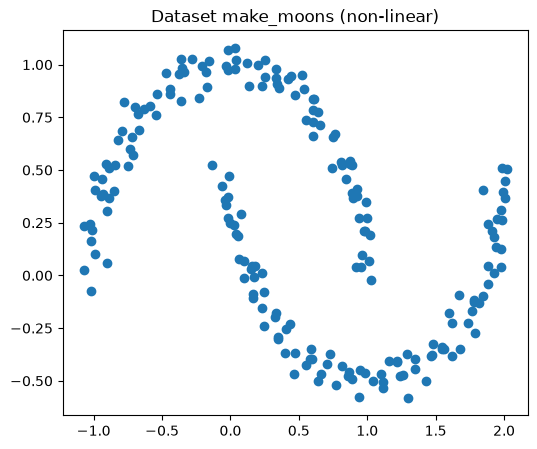

In [3]:
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1])
plt.title('Dataset make_moons (non-linear)')
plt.show()

Secara visual jelas ada **dua kelompok** (bulan atas dan bulan bawah). Pertanyaannya:
bisakah K-Means menemukannya?

## Langkah 2 - Klasterisasi dengan K-Means

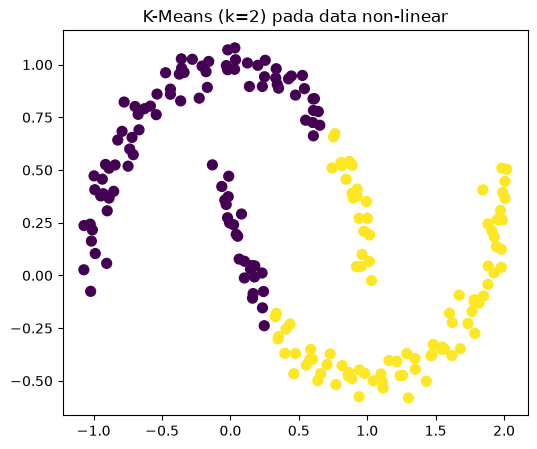

In [4]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, random_state=0, n_init=10)
cluster = kmeans.fit_predict(X)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=cluster, s=50, cmap='viridis')
plt.title('K-Means (k=2) pada data non-linear')
plt.show()

Hasilnya **salah**: K-Means membelah data berdasarkan jarak ke centroid, sehingga yang terpisah
adalah **kiri–kanan**, bukan **atas–bawah**. Setengah dari tiap bulan masuk ke cluster yang salah.

Evaluasi dengan *silhouette coefficient*:

In [5]:
from sklearn.metrics import silhouette_score

print('Silhouette score K-Means:', round(silhouette_score(X, cluster), 5))

Silhouette score K-Means: 0.49216


Nilai *silhouette* sekitar **0,49** — terlihat "cukup" padahal hasilnya secara visual salah.
Ini menunjukkan bahwa **metrik internal tidak selalu sejalan dengan kebenaran semantik cluster**;
inspeksi visual tetap penting.

## Langkah 3 - Klasterisasi dengan DBSCAN

> **Penting:** DBSCAN sangat sensitif terhadap parameter `eps` (radius tetangga) dan
> `min_samples` (jumlah tetangga minimum agar sebuah titik dianggap *core point*).

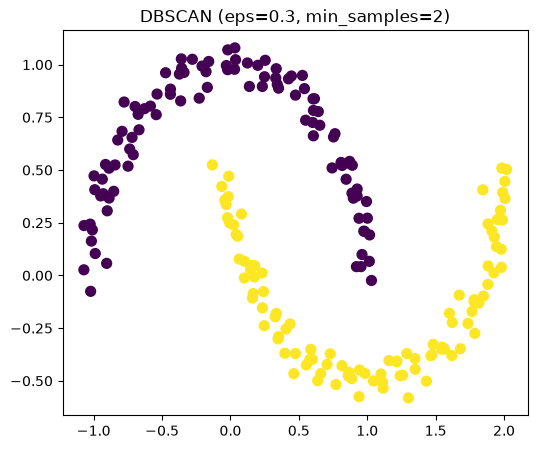

In [6]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.3, min_samples=2)
cluster_db = dbscan.fit_predict(X)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=cluster_db, s=50, cmap='viridis')
plt.title('DBSCAN (eps=0.3, min_samples=2)')
plt.show()

Sekarang kedua bulan terpisah dengan benar. DBSCAN menelusuri **keterhubungan kepadatan**:
titik-titik yang saling berdekatan dalam radius `eps` digabung ke cluster yang sama,
sehingga cluster boleh berbentuk apa pun (tidak harus bulat).

In [7]:
print('Silhouette score DBSCAN:', round(silhouette_score(X, cluster_db), 5))

Silhouette score DBSCAN: 0.32585


Nilai *silhouette* DBSCAN (sekitar **0,33**) justru **lebih rendah** daripada K-Means,
padahal secara visual DBSCAN jauh lebih benar. Mengapa?

**Silhouette coefficient mengasumsikan cluster terpisah secara linear/konveks** dan
mengukur jarak ke centroid. Pada cluster berbentuk bulan sabit yang melengkung, jarak
antar-titik dalam satu cluster bisa lebih besar daripada jarak ke cluster lain,
sehingga metrik ini tidak adil untuk DBSCAN.

Evaluasi yang lebih tepat untuk DBSCAN:
1. **Persentase noise** (titik berlabel `-1`).
2. **Inspeksi visual.**
3. **Davies-Bouldin Index (DBI)** — fokus pada separasi antar cluster; **semakin kecil semakin baik**
   (rentang 0 sampai tak hingga).

In [8]:
from sklearn.metrics import davies_bouldin_score

# Compute and print Davies-Bouldin Index
db = davies_bouldin_score(X, cluster_db)
print(f'Davies-Bouldin Index: {round(db, 5)}')

Davies-Bouldin Index: 1.16227


In [9]:
# Persentase noise dan jumlah cluster yang terbentuk
label_unik = set(cluster_db)
n_cluster = len(label_unik) - (1 if -1 in label_unik else 0)
n_noise = int((cluster_db == -1).sum())

print(f'Jumlah cluster : {n_cluster}')
print(f'Jumlah noise   : {n_noise} data ({n_noise / len(cluster_db) * 100:.2f}%)')

Jumlah cluster : 2
Jumlah noise   : 0 data (0.00%)


## Langkah 4 (Tambahan) - Uji Sensitivitas Parameter `eps`

Karena DBSCAN sensitif terhadap `eps`, mari kita lihat perilakunya pada beberapa nilai `eps`
dengan `min_samples` tetap.

In [10]:
hasil = []
for eps in [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]:
    lab = DBSCAN(eps=eps, min_samples=2).fit_predict(X)
    uniq = set(lab)
    n_cl = len(uniq) - (1 if -1 in uniq else 0)
    noise = (lab == -1).sum() / len(lab) * 100
    sil = silhouette_score(X, lab) if n_cl > 1 else np.nan
    dbi = davies_bouldin_score(X, lab) if n_cl > 1 else np.nan
    hasil.append({'eps': eps, 'jumlah_cluster': n_cl,
                  'noise (%)': round(noise, 2),
                  'silhouette': round(sil, 4) if sil == sil else None,
                  'DBI': round(dbi, 4) if dbi == dbi else None})

pd.DataFrame(hasil)

,eps,jumlah_cluster,noise (%),silhouette,DBI
0,0.10,12,3.5,0.2612,2.2868
1,0.15,2,0.0,0.3259,1.1623
2,0.20,2,0.0,0.3259,1.1623
3,0.25,2,0.0,0.3259,1.1623
4,0.30,2,0.0,0.3259,1.1623
5,0.40,1,0.0,NaN,NaN
6,0.50,1,0.0,NaN,NaN


**Interpretasi tabel:**
- `eps` terlalu kecil -> cluster pecah menjadi banyak bagian (atau hampir semua jadi noise).
- `eps` terlalu besar -> semua data menyatu menjadi **satu** cluster.
- Nilai `eps` yang baik adalah yang menghasilkan jumlah cluster **stabil** dan noise **rendah**.

Untuk data ini, `eps = 0.3` (dengan `min_samples = 2`) memberi hasil terbaik: 2 cluster,
tanpa noise, sesuai dengan struktur dua bulan pada data. Perhatikan bahwa rentang `eps = 0,15–0,3`
memberi hasil yang **sama** — inilah tanda parameter yang stabil. Nilai `0,3` dipilih karena berada
di tengah rentang stabil tersebut: cukup jauh dari batas bawah (di bawah 0,15 cluster mulai pecah)
dan cukup jauh dari batas atas (di atas 0,3 kedua bulan mulai menyatu menjadi satu cluster).

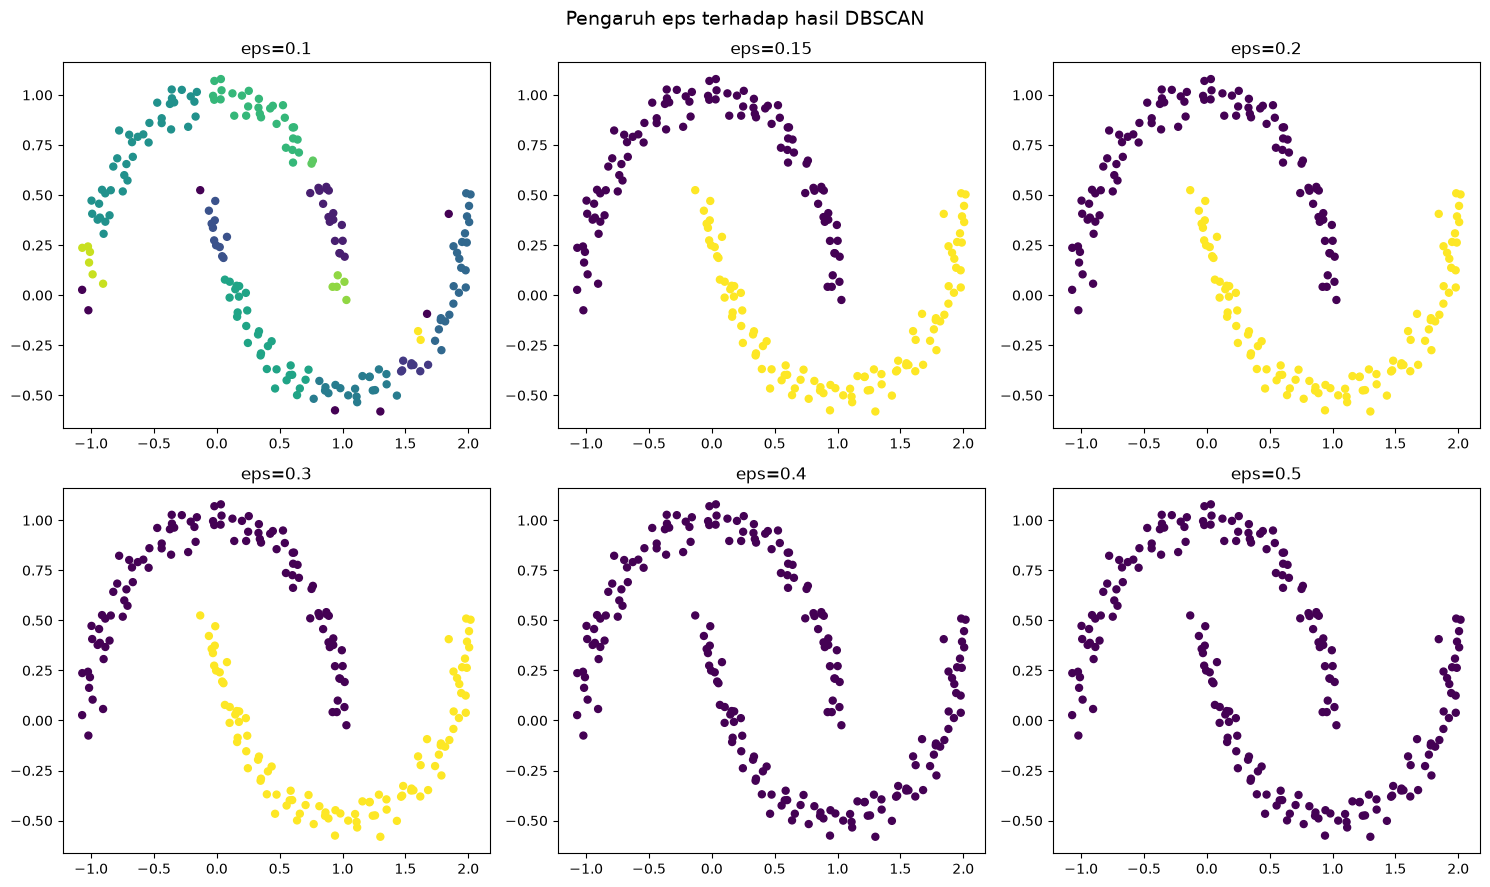

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, eps in zip(axes.ravel(), [0.1, 0.15, 0.2, 0.3, 0.4, 0.5]):
    lab = DBSCAN(eps=eps, min_samples=2).fit_predict(X)
    ax.scatter(X[:, 0], X[:, 1], c=lab, s=25, cmap='viridis')
    ax.set_title(f'eps={eps}')
plt.suptitle('Pengaruh eps terhadap hasil DBSCAN', size=14)
plt.tight_layout()
plt.show()

## Kesimpulan Lab 2
1. **K-Means gagal** pada data non-linear berbentuk bulan sabit: batas cluster-nya selalu linear,
   sehingga cluster terbelah kiri–kanan, bukan atas–bawah.
2. **DBSCAN berhasil** memisahkan kedua bulan karena bekerja berdasarkan **kepadatan** dan
   keterhubungan titik, bukan jarak ke centroid.
3. **Silhouette score menyesatkan** pada data non-linear: nilainya lebih rendah untuk DBSCAN
   (0,33) dibanding K-Means (0,49), padahal DBSCAN yang benar secara visual.
   Gunakan **DBI (semakin kecil semakin baik)**, **persentase noise**, dan **inspeksi visual**
   sebagai pelengkap.
4. DBSCAN sangat sensitif terhadap `eps` dan `min_samples`; nilainya harus diuji, bukan ditebak.